# Breast Cancer Wisconsin — Diagnostic

### Context

Clinical imaging dataset describing breast masses using quantitative characteristics extracted from digitised images of fine-needle aspirates. The variables describe different morphological properties of cell nuclei.

### Dimensionality and Structure

The dataset contains 569 samples described by 30 continuous variables. Each sample is associated with a binary diagnosis: benign or malignant.


### Possible Questions
- Supervised learning: Predict whether a breast mass is benign or malignant.
- Unsupervised learning: Determine whether samples naturally separate into groups corresponding to benign and malignant diagnoses.
- Additional analysis: Identify the morphological variables that are the most discriminative.


### Descriptif des données

#### Catégories
_mean : La moyenne arithmétique de la caractéristique mesurée sur l'ensemble des noyaux cellulaires analysés dans l'image.

_se (Standard Error) : L'erreur type, qui quantifie la variabilité ou la dispersion des mesures au sein de l'échantillon cellulaire.

_worst : La valeur "maximale" ou pire cas, calculée comme la moyenne des trois valeurs les plus élevées observées, ciblant les cellules les plus agressives ou atypiques.

.

#### Variables
Radius : La distance moyenne entre le centre géométrique du noyau et les points situés sur son périmètre.

Texture : L'écart-type des niveaux de gris, mesurant les variations de luminosité et l'aspect granuleux de la surface cellulaire.

Perimeter : La longueur totale du contour extérieur qui enveloppe le noyau cellulaire.

Area : La surface totale à deux dimensions occupée par le noyau de la cellule.

Smoothness : Les variations locales des longueurs de rayon, évaluant la régularité ou le caractère rugueux du bord.

Compactness : Le rapport mathématique entre le périmètre au carré et l'aire, traduisant la compacité et la rondeur de la forme.

Concavity : La sévérité et la profondeur des portions creuses ou rentrantes observées le long du contour.

Concave Points : Le nombre total de points d'inflexion ou de creux distincts identifiés sur la bordure.

Symmetry : Le degré de correspondance symétrique de la forme du noyau par rapport à ses axes médians.

Fractal Dimension : Une approximation de la complexité géométrique et de l'irrégularité structurelle du contour.

----------------------------------------------------------------
# Imports

In [62]:
import pandas as pd

import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.decomposition import PCA
from sklearn.cluster import KMeans


--------------------------
# Chargement des données

In [63]:
data = pd.read_csv("10_Breast_Cancer_Wisconsin_Diagnostic.csv")
print(data.shape)
data.head()

(569, 32)


,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave_points_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave_points_worst,symmetry_worst,fractal_dimension_worst
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


diagnosis
B    357
M    212
Name: count, dtype: int64
diagnosis
B    62.741652
M    37.258348
Name: proportion, dtype: float64


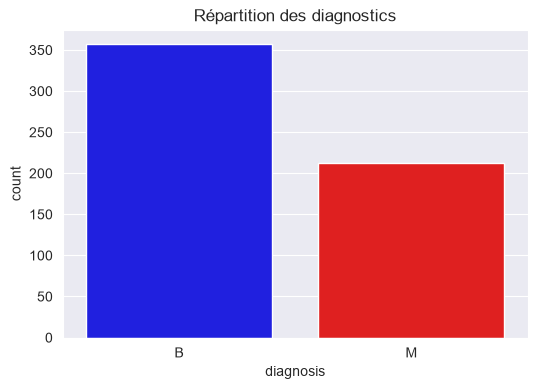

In [64]:
print(data['diagnosis'].value_counts())
print(data['diagnosis'].value_counts(normalize=True) * 100)

plt.figure(figsize=(6, 4))
sns.countplot(
    data=data, 
    x='diagnosis', 
    hue='diagnosis', 
    palette={'B': 'blue', 'M': 'red'}, 
    order=['B', 'M'], 
    legend=False
)
plt.title('Répartition des diagnostics')
plt.show()

------------------------------
# Pré-traitements

In [65]:
from sklearn.preprocessing import StandardScaler

print(data.columns)

### Supprimer colonne id
data = data.drop(['id'], axis=1)

### Binariser 'diagnosis'
data['diagnosis_num'] = data['diagnosis'].map({'M': 1, 'B': 0})

X_eda = data.drop(['diagnosis', 'diagnosis_num'], axis=1)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_eda)

Index(['id', 'diagnosis', 'radius_mean', 'texture_mean', 'perimeter_mean',
       'area_mean', 'smoothness_mean', 'compactness_mean', 'concavity_mean',
       'concave_points_mean', 'symmetry_mean', 'fractal_dimension_mean',
       'radius_se', 'texture_se', 'perimeter_se', 'area_se', 'smoothness_se',
       'compactness_se', 'concavity_se', 'concave_points_se', 'symmetry_se',
       'fractal_dimension_se', 'radius_worst', 'texture_worst',
       'perimeter_worst', 'area_worst', 'smoothness_worst',
       'compactness_worst', 'concavity_worst', 'concave_points_worst',
       'symmetry_worst', 'fractal_dimension_worst'],
      dtype='str')


In [66]:
X_scaled

array([[ 1.09706398, -2.07333501,  1.26993369, ...,  2.29607613,
         2.75062224,  1.93701461],
       [ 1.82982061, -0.35363241,  1.68595471, ...,  1.0870843 ,
        -0.24388967,  0.28118999],
       [ 1.57988811,  0.45618695,  1.56650313, ...,  1.95500035,
         1.152255  ,  0.20139121],
       ...,
       [ 0.70228425,  2.0455738 ,  0.67267578, ...,  0.41406869,
        -1.10454895, -0.31840916],
       [ 1.83834103,  2.33645719,  1.98252415, ...,  2.28998549,
         1.91908301,  2.21963528],
       [-1.80840125,  1.22179204, -1.81438851, ..., -1.74506282,
        -0.04813821, -0.75120669]], shape=(569, 30))

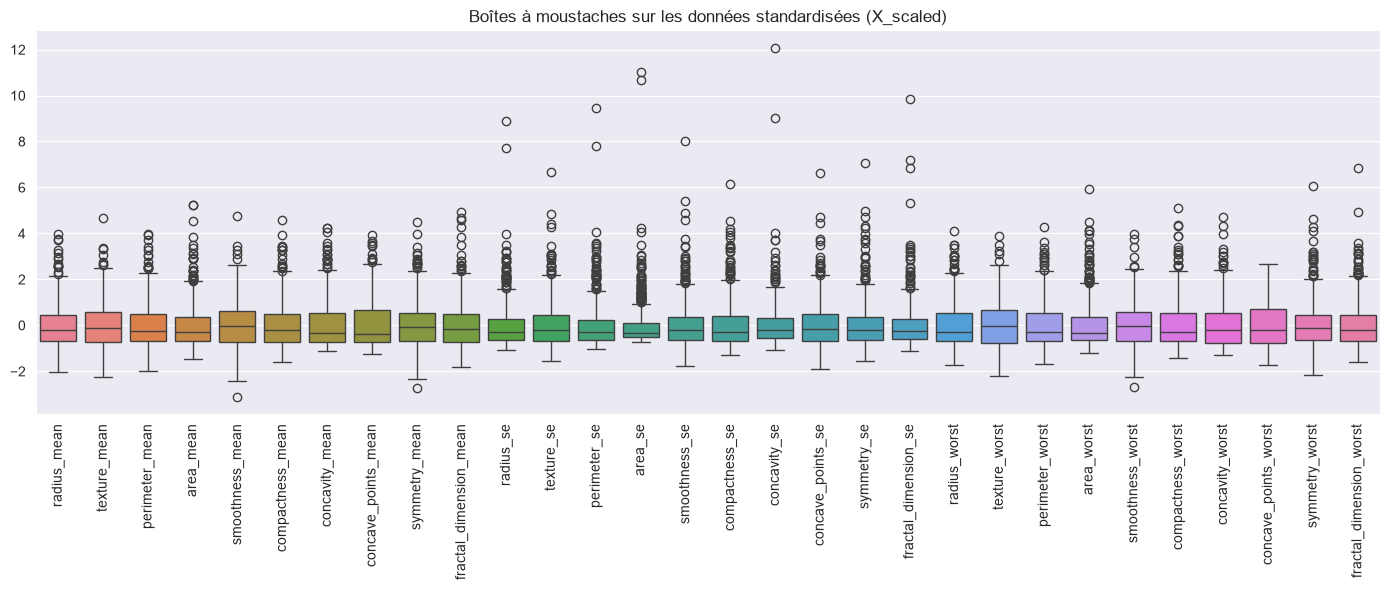

In [67]:
# Outliers ?
df_scaled = pd.DataFrame(X_scaled, columns=X_eda.columns)

plt.figure(figsize=(14, 6))
sns.boxplot(data=df_scaled)
plt.xticks(rotation=90)
plt.title("Boîtes à moustaches sur les données standardisées (X_scaled)")
plt.tight_layout()
plt.show()

-------------------------------------
# Test corrélations

diagnosis_num              1.000000
concave_points_worst       0.793566
perimeter_worst            0.782914
concave_points_mean        0.776614
radius_worst               0.776454
perimeter_mean             0.742636
area_worst                 0.733825
radius_mean                0.730029
area_mean                  0.708984
concavity_mean             0.696360
concavity_worst            0.659610
compactness_mean           0.596534
compactness_worst          0.590998
radius_se                  0.567134
perimeter_se               0.556141
area_se                    0.548236
texture_worst              0.456903
smoothness_worst           0.421465
symmetry_worst             0.416294
texture_mean               0.415185
concave_points_se          0.408042
smoothness_mean            0.358560
symmetry_mean              0.330499
fractal_dimension_worst    0.323872
compactness_se             0.292999
concavity_se               0.253730
fractal_dimension_se       0.077972
symmetry_se               -0

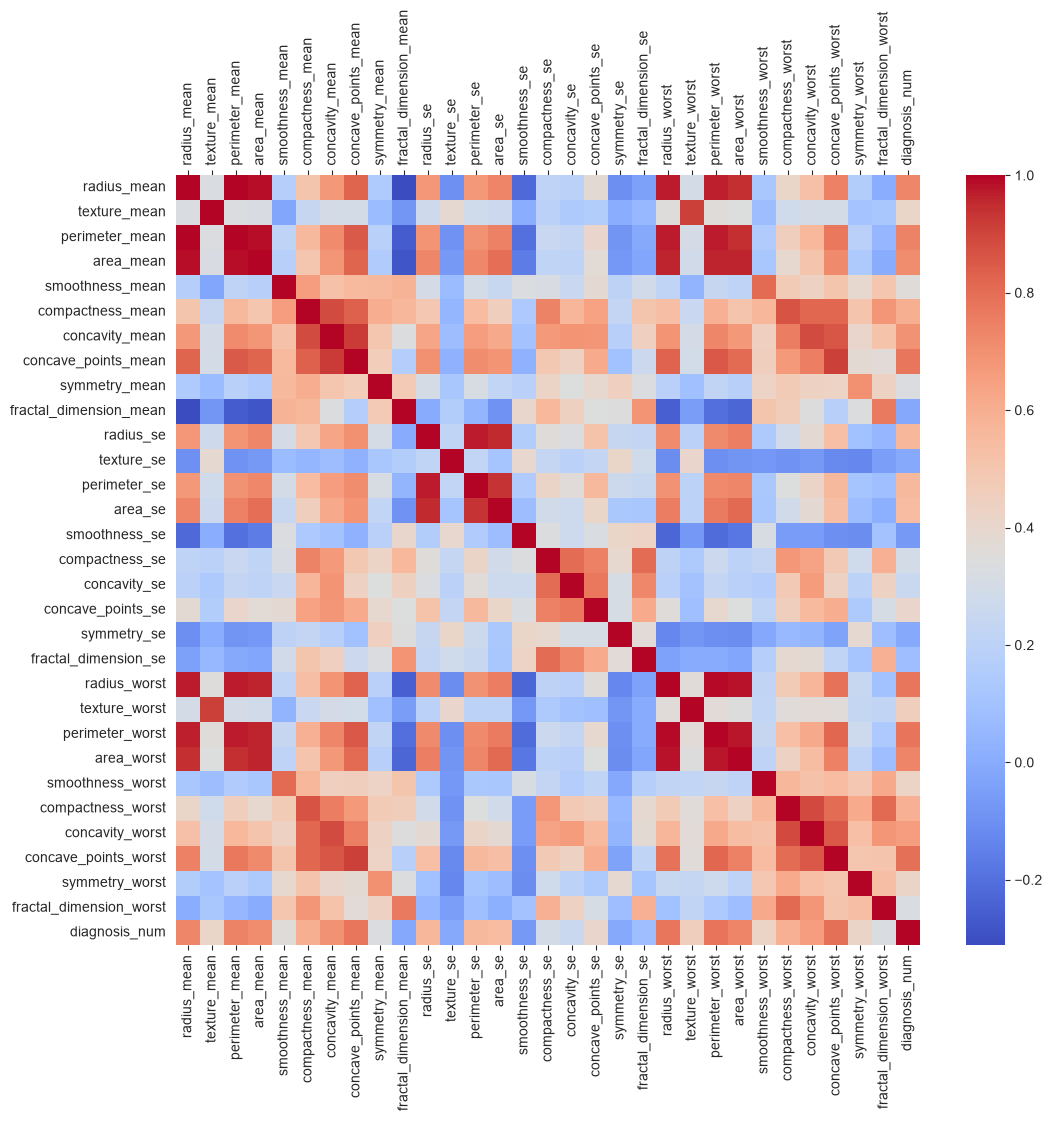

In [68]:
corr_matrix = data.select_dtypes(exclude=['object']).corr()
print(corr_matrix['diagnosis_num'].sort_values(ascending=False))

plt.figure(figsize=(12, 10))
ax = sns.heatmap(corr_matrix, cmap='coolwarm', annot=False)

ax.tick_params(top=True, labeltop=True, bottom=True, labelbottom=True)
plt.xticks(rotation=90)

plt.show()

---------------------
# PCA

In [69]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

variance_pc1 = pca.explained_variance_ratio_[0]
variance_pc2 = pca.explained_variance_ratio_[1]
variance_totale = pca.explained_variance_ratio_.sum()

print(f"Variance de PC1 : {variance_pc1:.2%}")
print(f"Variance de PC2 : {variance_pc2:.2%}")
print(f"Variance cumulée (PC1 + PC2) : {variance_totale:.2%}")

loadings = pd.DataFrame(pca.components_.T, columns=['PC1', 'PC2'], index=X_eda.columns)
top_pc1 = loadings.abs().sort_values(by='PC1', ascending=False).head(5)
print(top_pc1)

Variance de PC1 : 44.27%
Variance de PC2 : 18.97%
Variance cumulée (PC1 + PC2) : 63.24%
                           PC1       PC2
concave_points_mean   0.260854  0.034768
concavity_mean        0.258400  0.060165
concave_points_worst  0.250886  0.008257
compactness_mean      0.239285  0.151892
perimeter_worst       0.236640  0.199878


---------------------------
# Test KMeans

--------------Metrics--------------
Homogeneity: 0.525
Completeness: 0.540
V-measure: 0.532
Adjusted Rand-Index: 0.654
Silhouette Coefficient: 0.343


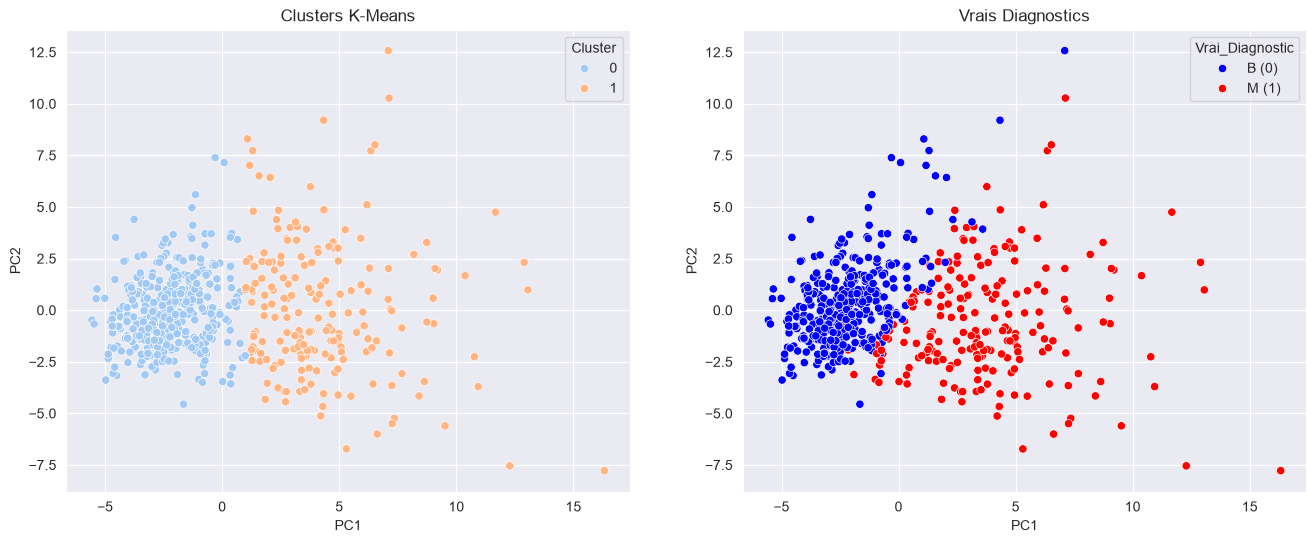

In [70]:
from sklearn import metrics

kmeans = KMeans(n_clusters=2, init='k-means++', max_iter=100, n_init=10, random_state=42)
clusters = kmeans.fit_predict(X_scaled)

homogeneity = metrics.homogeneity_score(data['diagnosis_num'], clusters)
completeness = metrics.completeness_score(data['diagnosis_num'], clusters)
v_measure = metrics.v_measure_score(data['diagnosis_num'], clusters)
ari = metrics.adjusted_rand_score(data['diagnosis_num'], clusters)
silhouette = metrics.silhouette_score(X_scaled, clusters)

print("--------------Metrics--------------")
print(f"Homogeneity: {homogeneity:.3f}")
print(f"Completeness: {completeness:.3f}")
print(f"V-measure: {v_measure:.3f}")
print(f"Adjusted Rand-Index: {ari:.3f}")
print(f"Silhouette Coefficient: {silhouette:.3f}") # Compris entre -1 et 1, évalue la qualité de la séparation (1=séparation parfaite) ; calculé avec cohésion (distance entre un point et les autres points de son cluster) et séparation (distance entre un point et les points du cluster voisin)
# https://scikit-learn.org/stable/modules/clustering.html#k-means

df_viz = pd.DataFrame(X_pca, columns=['PC1', 'PC2'])
df_viz['Cluster'] = clusters
df_viz['Vrai_Diagnostic'] = data['diagnosis'].map({'B': 'B (0)', 'M': 'M (1)'})

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.scatterplot(data=df_viz, x='PC1', y='PC2', hue='Cluster', palette='pastel', ax=axes[0])
axes[0].set_title('Clusters K-Means')

sns.scatterplot(
    data=df_viz, 
    x='PC1', 
    y='PC2', 
    hue='Vrai_Diagnostic',
    hue_order=['B (0)', 'M (1)'],
    palette={'B (0)': 'blue', 'M (1)': 'red'}, 
    ax=axes[1]
)
axes[1].set_title('Vrais Diagnostics')

plt.show()

**Homogénéité** : Cette métrique évalue la pureté de chaque cluster en vérifiant si ses membres appartiennent à une seule et même classe réelle.Principe mathématique : Elle utilise l'entropie conditionnelle $H(K\vert{}C)$, qui quantifie l'incertitude sur la classe réelle d'un point connaissant son cluster d'appartenance.Formule :$$h = 1 - \frac{H(K\vert{}C)}{H(K)}$$Interprétation : Si chaque cluster ne contient strictement que des cellules d'un seul diagnostic (par exemple, que des cas bénins), l'entropie conditionnelle est nulle et l'homogénéité atteint 1.0.

---------------------------

**Complétude** : Elle mesure l'effet inverse : elle vérifie si tous les éléments d'une même classe réelle sont regroupés au sein du même cluster.Principe mathématique : Elle s'appuie sur l'entropie conditionnelle inverse $H(C\vert{}K)$, mesurant l'incertitude sur le cluster d'un point connaissant sa classe réelle.Formule :$$c = 1 - \frac{H(C\vert{}K)}{H(C)}$$Interprétation : Si tous les cas malins sont rassemblés dans un unique cluster sans dispersion, la complétude atteint 1.0.

----------------------------

**V-measure** : Cette métrique combine l'homogénéité et la complétude pour fournir un score unique de performance.Principe mathématique : Il s'agit de la moyenne harmonique pondérée des deux scores précédents.Formule :$$v = \frac{2 \cdot h \cdot c}{h + c}$$Interprétation : Tout comme une moyenne harmonique en physique ou en électronique, elle sanctionne sévèrement un déséquilibre : si l'homogénéité est excellente mais que la complétude est mauvaise, la V-measure s'effondre.

----------------------------

**Adjusted Rand-Index (ARI)** : L'ARI mesure la similarité géométrique globale entre le partitionnement de l'algorithme et les étiquettes réelles, en comptant les paires d'échantillons.Principe mathématique : Il examine toutes les paires possibles de points et vérifie si elles sont classées ensemble ou séparément dans les deux systèmes (clustering vs diagnostic).Correction du hasard : L'indice brut est normalisé et ajusté par rapport à une valeur espérée sous l'hypothèse d'une attribution purement aléatoire.Formule :$$\text{ARI} = \frac{\text{RI} - \text{Expected RI}}{\text{Max(RI)} - \text{Expected RI}}$$Interprétation : Un score de 0.0 indique un résultat équivalent au hasard statistique, tandis que 1.0 représente un accord parfait entre les clusters et la réalité clinique.

--------------------------

**Silhouette Coefficient** : se calcule en mesurant simultanément la cohésion d'un point au sein de son propre groupe et sa séparation par rapport aux autres groupes.Pour chaque point de données $i$, le calcul s'effectue en deux étapes :
- **Cohésion** $a(i)$ : La distance moyenne entre le point $i$ et tous les autres points appartenant à son propre cluster. Plus cette distance est petite, plus le point est bien intégré à son groupe.
- **Séparation** $b(i)$ : La distance moyenne entre le point $i$ et tous les points du cluster voisin le plus proche (le groupe distinct minimisant cette distance moyenne).

Le coefficient de silhouette individuel $s(i)$ pour ce point s'obtient avec la formule :$$s(i) = \frac{b(i) - a(i)}{\max(a(i), b(i))}$$Le score global que vous avez calculé (0.343) est la moyenne de ces scores individuels $s(i)$ sur l'ensemble des données.Interprétation mathématiqueTendant vers 1 : $a(i) \ll b(i)$. Le point est très proche de son propre cluster et très éloigné des autres. Le clustering est optimal.Proche de 0 : $a(i) \approx b(i)$. Le point se trouve exactement à la frontière entre deux clusters.Tendant vers -1 : $a(i) \gg b(i)$. Le point est en moyenne plus proche des membres d'un autre cluster que du sien, indiquant une erreur de classification géométrique.

----------------
# Hierarchichal Clustering

--- Hierarchical Clustering Metrics ---

Linkage: Ward
  Homogeneity: 0.446
  Completeness: 0.468
  V-measure: 0.457
  Adjusted Rand-Index: 0.575
  Silhouette Coefficient: 0.339

Linkage: Average
  Homogeneity: 0.008
  Completeness: 0.159
  V-measure: 0.015
  Adjusted Rand-Index: 0.007
  Silhouette Coefficient: 0.634

Linkage: Complete
  Homogeneity: 0.005
  Completeness: 0.149
  V-measure: 0.010
  Adjusted Rand-Index: 0.005
  Silhouette Coefficient: 0.661


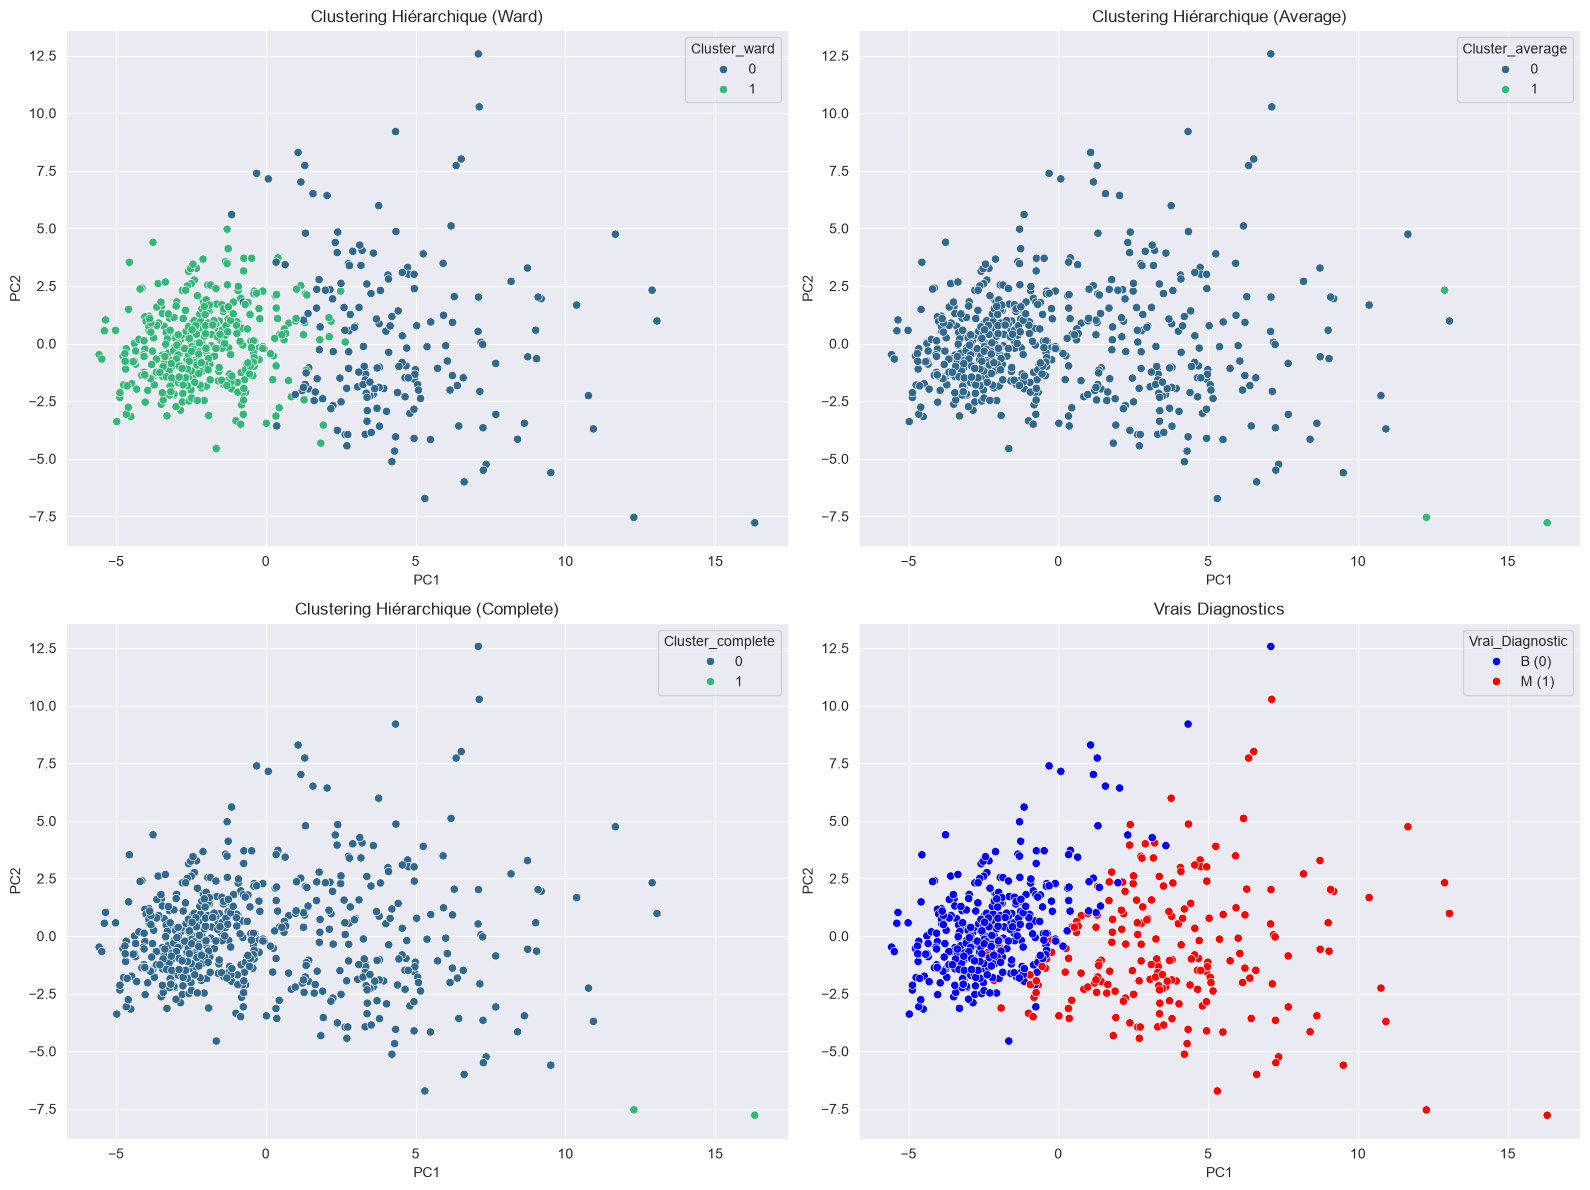

In [71]:
from sklearn.cluster import AgglomerativeClustering

df_viz_hc = pd.DataFrame(X_pca, columns=['PC1', 'PC2'])
df_viz_hc['Vrai_Diagnostic'] = data['diagnosis'].map({'B': 'B (0)', 'M': 'M (1)'})

fig, axes = plt.subplots(2, 2, figsize=(16, 12))
axes = axes.flatten()

linkages = ['ward', 'average', 'complete']

print("--- Hierarchical Clustering Metrics ---")
for i, linkage in enumerate(linkages):
    clustering = AgglomerativeClustering(linkage=linkage, n_clusters=2)
    clusters_hc = clustering.fit_predict(X_scaled)
    
    homogeneity = metrics.homogeneity_score(data['diagnosis_num'], clusters_hc)
    completeness = metrics.completeness_score(data['diagnosis_num'], clusters_hc)
    v_measure = metrics.v_measure_score(data['diagnosis_num'], clusters_hc)
    ari = metrics.adjusted_rand_score(data['diagnosis_num'], clusters_hc)
    silhouette = metrics.silhouette_score(X_scaled, clusters_hc)
    
    print(f"\nLinkage: {linkage.capitalize()}")
    print(f"  Homogeneity: {homogeneity:.3f}")
    print(f"  Completeness: {completeness:.3f}")
    print(f"  V-measure: {v_measure:.3f}")
    print(f"  Adjusted Rand-Index: {ari:.3f}")
    print(f"  Silhouette Coefficient: {silhouette:.3f}")
    
    df_viz_hc[f'Cluster_{linkage}'] = clusters_hc
    
    sns.scatterplot(data=df_viz_hc, x='PC1', y='PC2', hue=f'Cluster_{linkage}', palette='viridis', ax=axes[i])
    axes[i].set_title(f'Clustering Hiérarchique ({linkage.capitalize()})')

sns.scatterplot(
    data=df_viz_hc, 
    x='PC1', 
    y='PC2', 
    hue='Vrai_Diagnostic',
    hue_order=['B (0)', 'M (1)'],
    palette={'B (0)': 'blue', 'M (1)': 'red'}, 
    ax=axes[3]
)
axes[3].set_title('Vrais Diagnostics')

plt.tight_layout()
plt.show()

Linkages "Average" et "Complete" ne fonctionnent pas du tout pour ces données...

Le linkage "Ward" n'arrive pas mieux que le KMeans à séparer les deux groupes

---------------------------------
# Spectral Clustering

--- Spectral Clustering ---
Homogeneity: 0.650
Completeness: 0.676
V-measure: 0.663
Adjusted Rand-Index: 0.761
Silhouette Coefficient: 0.337


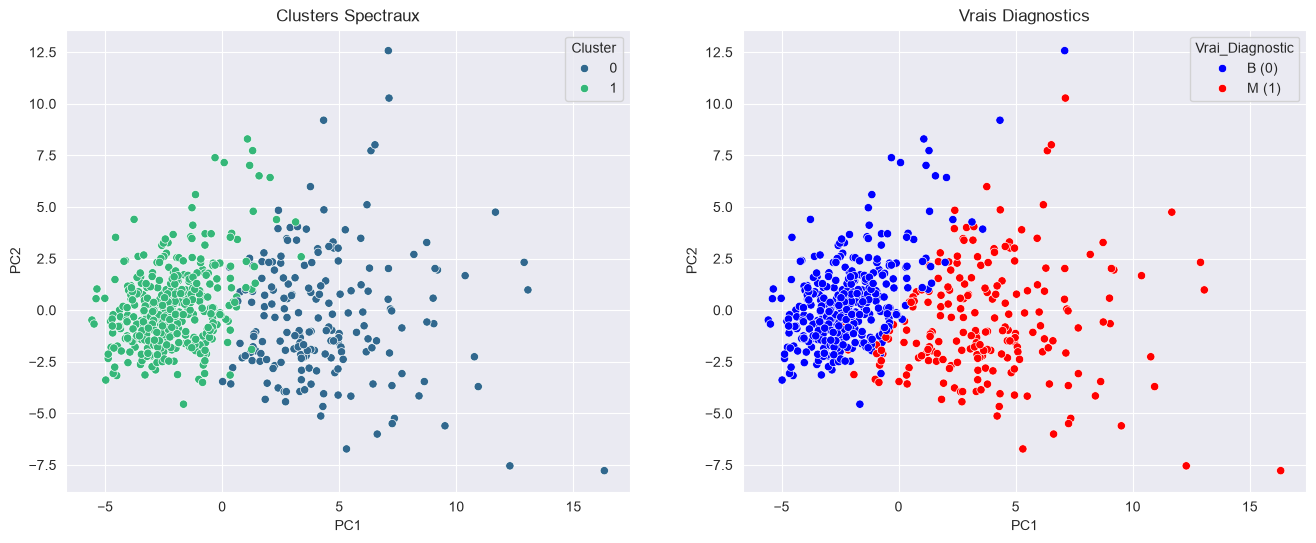

In [72]:
from sklearn.cluster import SpectralClustering
from sklearn import metrics
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

spectral = SpectralClustering(
    n_clusters=2, 
    eigen_solver='arpack', 
    affinity='nearest_neighbors', 
    random_state=42
)
clusters_spectral = spectral.fit_predict(X_scaled)

homogeneity = metrics.homogeneity_score(data['diagnosis_num'], clusters_spectral)
completeness = metrics.completeness_score(data['diagnosis_num'], clusters_spectral)
v_measure = metrics.v_measure_score(data['diagnosis_num'], clusters_spectral)
ari_spec = metrics.adjusted_rand_score(data['diagnosis_num'], clusters_spectral)
silhouette_spec = metrics.silhouette_score(X_scaled, clusters_spectral)

print("--- Spectral Clustering ---")
print(f"Homogeneity: {homogeneity:.3f}")
print(f"Completeness: {completeness:.3f}")
print(f"V-measure: {v_measure:.3f}")
print(f"Adjusted Rand-Index: {ari_spec:.3f}")
print(f"Silhouette Coefficient: {silhouette_spec:.3f}")

df_viz_spec = pd.DataFrame(X_pca, columns=['PC1', 'PC2'])
df_viz_spec['Cluster'] = clusters_spectral
df_viz_spec['Vrai_Diagnostic'] = data['diagnosis'].map({'B': 'B (0)', 'M': 'M (1)'})

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.scatterplot(data=df_viz_spec, x='PC1', y='PC2', hue='Cluster', palette='viridis', ax=axes[0])
axes[0].set_title('Clusters Spectraux')

sns.scatterplot(
    data=df_viz_spec, 
    x='PC1', 
    y='PC2', 
    hue='Vrai_Diagnostic',
    hue_order=['B (0)', 'M (1)'],
    palette={'B (0)': 'blue', 'M (1)': 'red'}, 
    ax=axes[1]
)
axes[1].set_title('Vrais Diagnostics')

plt.show()

In [30]:
### Séparation des données (Train/Test Split)

In [ ]:
### Feature Selection (APRèS la séparation train/test pour éviter data leakage)
variables = [
    "perimeter_worst",
    ""
]